In [2]:
!pip install wordcloud

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

nltk.download('stopwords')
nltk.download('punkt')

df = pd.read_csv('spam.csv', encoding='latin-1')

df = df[['v1', 'v2']]
df.columns = ['label', 'message']


df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

display(df.head())

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.


,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


Class Counts:
 label
ham     4825
spam     747
Name: count, dtype: int64

Class Percentages:
 label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


C:\Users\dell\AppData\Local\Temp\ipykernel_18540\2143061989.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette=['green', 'red'])


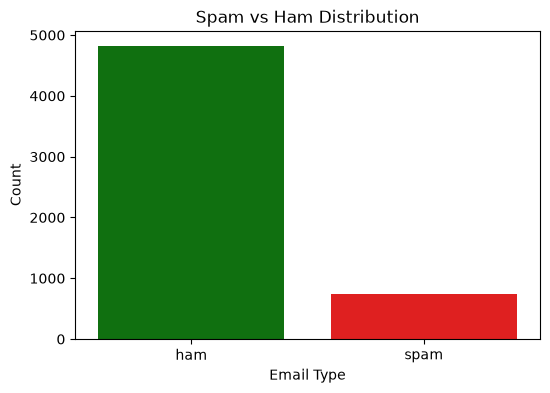

In [4]:
class_counts = df['label'].value_counts()
class_percentages = df['label'].value_counts(normalize=True) * 100

print("Class Counts:\n", class_counts)
print("\nClass Percentages:\n", class_percentages)

# رسم التوزيع
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', palette=['green', 'red'])
plt.title('Spam vs Ham Distribution')
plt.xlabel('Email Type')
plt.ylabel('Count')
plt.show()

In [5]:
stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    
    text = text.lower()
    
    text = re.sub(r'[^a-z\s]', '', text)
   
    words = text.split()
    processed_words = [stemmer.stem(word) for word in words if word not in stop_words]
    return ' '.join(processed_words)
    
df['cleaned_message'] = df['message'].apply(preprocess_text)

display(df[['message', 'cleaned_message']].head())

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goe usf live around though


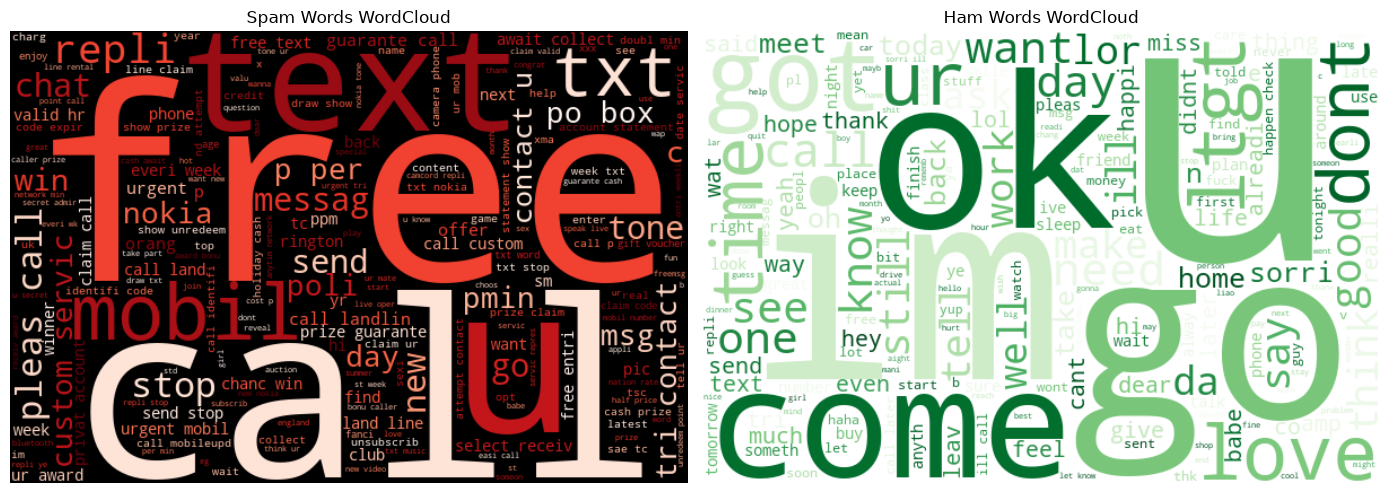

In [6]:
# فصل النصوص بناءً على التصنيف
spam_texts = ' '.join(df[df['label'] == 'spam']['cleaned_message'])
ham_texts = ' '.join(df[df['label'] == 'ham']['cleaned_message'])

plt.figure(figsize=(14, 6))

# سحابة كلمات البريد المزعج (Spam)
plt.subplot(1, 2, 1)
spam_wordcloud = WordCloud(width=600, height=400, background_color='black', colormap='Reds').generate(spam_texts)
plt.imshow(spam_wordcloud, interpolation='bilinear')
plt.title('Spam Words WordCloud')
plt.axis('off')

# سحابة كلمات البريد السليم (Ham)
plt.subplot(1, 2, 2)
ham_wordcloud = WordCloud(width=600, height=400, background_color='white', colormap='Greens').generate(ham_texts)
plt.imshow(ham_wordcloud, interpolation='bilinear')
plt.title('Ham Words WordCloud')
plt.axis('off')

plt.tight_layout()
plt.show()

In [9]:
# استخراج الميزات باستخدام TF-IDF
tfidf = TfidfVectorizer(max_features=3000)
X = tfidf.fit_transform(df['cleaned_message']).toarray()
y = df['label_num']

# تقسيم البيانات (80% تدريب - 20% اختبار)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training Data Shape: {X_train.shape}")
print(f"Testing Data Shape: {X_test.shape}")

Training Data Shape: (4457, 3000)
Testing Data Shape: (1115, 3000)


--- Multinomial Naive Bayes Evaluation ---
Accuracy:  0.9731
Precision: 0.9917
Recall:    0.8054
F1-Score:  0.8889



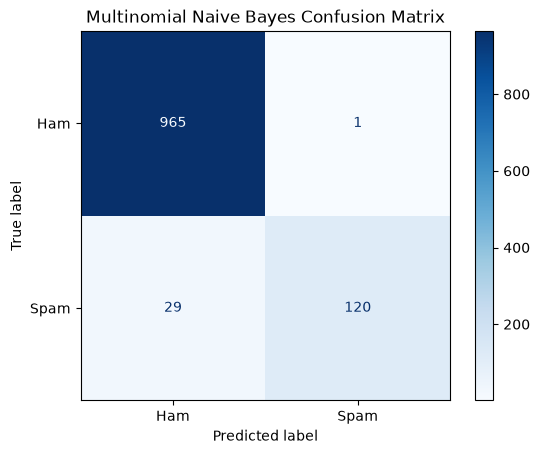

--- Logistic Regression Evaluation ---
Accuracy:  0.9659
Precision: 0.9912
Recall:    0.7517
F1-Score:  0.8550



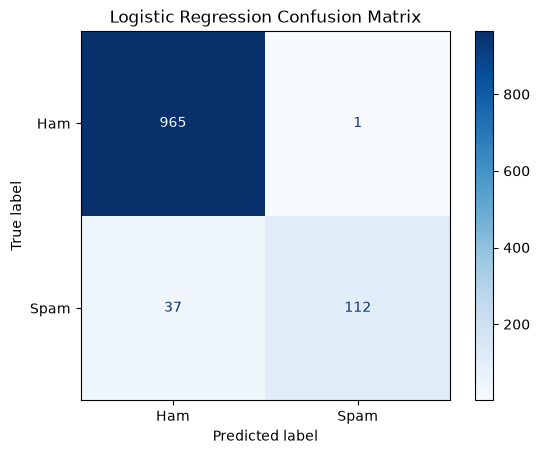

In [10]:
# دالة لتقييم النماذج وطباعة النتائج
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    
    print(f"--- {model_name} Evaluation ---")
    print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
    print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}\n")
    
    # (Confusion Matrix)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham', 'Spam'])
    disp.plot(cmap='Blues', values_format='d')
    plt.title(f'{model_name} Confusion Matrix')
    plt.show()

# النموذج الأول: Multinomial Naive Bayes (Standard for Text)
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
evaluate_model(nb_model, X_test, y_test, "Multinomial Naive Bayes")

# النموذج الثاني: Logistic Regression (Alternative Classifier)
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)
evaluate_model(lr_model, X_test, y_test, "Logistic Regression")